# **Exploratory Data Analysis (EDA) & Distributed Data Processing with Apache Spark**

# End-to-End Implementation
- **Module**: Distributed Machine Learning
- **Dataset**: [bank.csv](https://drive.google.com/file/d/17dekep3p_WYdegUvSmVK8vRaGwOguJiT/view?usp=sharing)

# Github Link
https://github.com/saiabhiram-simhadri/financial-forecasting-distributed-ml

# Spark Analysis

## Initial Setup

In [ ]:
import textwrap

def custom_display(
    title: str | None = None,
    content: str | list[str] | None = None,
    max_width: int = 70,
    padding: int = 2
):
    """
    Renders structured text inside a Unicode box.
    - Centers the title/header if the content width spans wider.
    - Supports (title, content), (content), or (title) dynamically.
    - Honors explicit '\n' line breaks and wraps unbroken lines exceeding max_width.
    """
    pad_space = " " * padding

    # Handle single positional argument intended as content
    if content is None and title is not None and ('\n' in title or len(title) > max_width):
        content = title
        title = None

    # Parse and wrap content lines
    formatted_lines = []
    if content is not None:
        if isinstance(content, str):
            raw_sections = content.split('\n')
        else:
            raw_sections = [line for item in content for line in str(item).split('\n')]

        for section in raw_sections:
            stripped = section.strip()
            if not stripped:
                formatted_lines.append("")
            elif len(section) > max_width:
                formatted_lines.extend(textwrap.wrap(section, width=max_width))
            else:
                formatted_lines.append(section)

    title_str = title.strip() if title else ""
    has_title = bool(title_str)
    has_content = bool(formatted_lines)

    if not has_title and not has_content:
        return

    # Calculate max width across both title and content
    max_content_len = max([len(line) for line in formatted_lines]) if has_content else 0
    max_line_len = max(len(title_str) if has_title else 0, max_content_len)

    inner_width = max_line_len + (padding * 2)

    # Render Box
    print(f"┌{'─' * inner_width}┐")
    if has_title:
        # Centers the header text across the total inner width
        print(f"│{title_str.center(inner_width)}│")
        if has_content:
            print(f"├{'─' * inner_width}┤")

    if has_content:
        for line in formatted_lines:
            print(f"│{pad_space}{line.ljust(max_line_len)}{pad_space}│")

    print(f"└{'─' * inner_width}┘")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Suppress non-critical warnings
warnings.filterwarnings("ignore")

%config InlineBackend.figure_format = 'retina'

CUSTOM_THEME = {
    'bg':       '#18191C',  # Soft Dark Slate Gray
    'card':     '#222428',  # Elevated Surface Card
    'grid':     '#32363C',  # Low-Contrast Grid Lines
    'text':     '#E3E5E8',  # Warm Off-White
    'subtext':  '#9B9D9E',  # Muted Axis Label Grey
    'teal':     '#2DD4BF',  # Soft Mint Teal
    'coral':    '#F87171',  # Soft Crimson Coral
    'purple':   '#A78BFA',  # Soft Amber Gold
    'orange':   '#FB923C',  # Soft Warm Orange
}

# Apply global parameters
plt.rcParams.update({
    'figure.facecolor':  CUSTOM_THEME['bg'],
    'axes.facecolor':    CUSTOM_THEME['card'],
    'savefig.facecolor': CUSTOM_THEME['bg'],
    'axes.edgecolor':    CUSTOM_THEME['grid'],
    'axes.labelcolor':   CUSTOM_THEME['text'],
    'xtick.color':       CUSTOM_THEME['subtext'],
    'ytick.color':       CUSTOM_THEME['subtext'],
    'grid.color':        CUSTOM_THEME['grid'],
    'grid.linestyle':    '--',
    'grid.alpha':        0.6,
    'text.color':        CUSTOM_THEME['text'],
})

## Environment Setup & PySpark Initialization
Configures `Java 11` and install native `pyspark`.

In [ ]:
# Install Java 17 (the most stable LTS version for PySpark on modern Ubuntu/Colab)
!apt-get update -qq > /dev/null
!apt-get install -y openjdk-17-jdk-headless -qq > /dev/null
!pip install -q pyspark py4j findspark

# Point JAVA_HOME strictly to Java 17
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

# Add Java 17 module opens required by PySpark's Py4J gateway
os.environ["PYSPARK_SUBMIT_ARGS"] = (
    "--driver-java-options \"--add-opens=java.base/java.lang=ALL-UNNAMED "
    "--add-opens=java.base/java.lang.invoke=ALL-UNNAMED "
    "--add-opens=java.base/java.lang.reflect=ALL-UNNAMED "
    "--add-opens=java.base/java.io=ALL-UNNAMED "
    "--add-opens=java.base/java.net=ALL-UNNAMED "
    "--add-opens=java.base/java.nio=ALL-UNNAMED "
    "--add-opens=java.base/java.util=ALL-UNNAMED "
    "--add-opens=java.base/java.util.concurrent=ALL-UNNAMED "
    "--add-opens=java.base/java.util.concurrent.atomic=ALL-UNNAMED "
    "--add-opens=java.base/sun.nio.ch=ALL-UNNAMED "
    "--add-opens=java.base/sun.nio.cs=ALL-UNNAMED "
    "--add-opens=java.base/sun.security.action=ALL-UNNAMED "
    "--add-opens=java.base/sun.util.calendar=ALL-UNNAMED\" "
    "pyspark-shell"
)

# Initialize findspark and verify Java path
import findspark
findspark.init()

!java -version
custom_display(f"Active JAVA_HOME: {os.environ['JAVA_HOME']}")

┌────────────────────────────────────────────────────────┐
│  Active JAVA_HOME: /usr/lib/jvm/java-17-openjdk-amd64  │
└────────────────────────────────────────────────────────┘


In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Bank_EDA_Spark_Processing") \
    .master("local[*]") \
    .config("spark.driver.memory", "4g") \
    .config("spark.sql.shuffle.partitions", "4") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")
custom_display(content=[
    "Apache Spark Session initialized successfully!",
    f"Spark Version: {spark.version}"
])

┌──────────────────────────────────────────────────┐
│  Apache Spark Session initialized successfully!  │
│  Spark Version: 4.0.4                            │
└──────────────────────────────────────────────────┘


## Task 1: Data Loading and Basic Inspection
* Load `bank.csv` into a Spark DataFrame.
* Show the first few rows.
* Print the schema.
* Display summary statistics for numerical columns.

In [ ]:
# Task 1: Load dataset into Spark DataFrame

# 1. Download the CSV locally using gdown
!pip install -q gdown
import gdown

CSV_FILE_ID = "17dekep3p_WYdegUvSmVK8vRaGwOguJiT"
download_url = f"https://drive.google.com/uc?id={CSV_FILE_ID}"
local_csv = "bank.csv"

gdown.download(download_url, local_csv, quiet=False)

# 2. Read local CSV into PySpark DataFrame
from pyspark.sql.types import IntegerType, DoubleType, LongType

df_spark = spark.read.csv(
    local_csv,
    header=True,
    inferSchema=True,
    sep=","   # explicitly specify comma delimiter
)

print(f"Total Rows: {df_spark.count():,} | Total Columns: {len(df_spark.columns)}")

# 1. Show first 5 rows
print("\n--- FIRST 5 ROWS ---")
df_spark.show(5, truncate=False)

# 2. Print Schema
print("\n--- SPARK DATAFRAME SCHEMA ---")
df_spark.printSchema()

# 3. Summary of Numerical Columns
print("\n--- SUMMARY STATISTICS OF NUMERICAL COLUMNS ---")
num_cols = [
    f.name for f in df_spark.schema.fields
    if isinstance(f.dataType, (IntegerType, DoubleType, LongType))
]
df_spark.select(num_cols).describe().show()

Downloading...
From: https://drive.google.com/uc?id=17dekep3p_WYdegUvSmVK8vRaGwOguJiT
To: /content/bank.csv
100%|██████████| 376k/376k [00:00<00:00, 10.1MB/s]


Total Rows: 4,521 | Total Columns: 17

--- FIRST 5 ROWS ---
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|job        |marital|education|default|balance|housing|loan|contact |day|month|duration|campaign|pdays|previous|poutcome|y  |
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|30 |unemployed |married|primary  |no     |1787   |no     |no  |cellular|19 |oct  |79      |1       |-1   |0       |unknown |no |
|33 |services   |married|secondary|no     |4789   |yes    |yes |cellular|11 |may  |220     |1       |339  |4       |failure |no |
|35 |management |single |tertiary |no     |1350   |yes    |no  |cellular|16 |apr  |185     |1       |330  |1       |failure |no |
|30 |management |married|tertiary |no     |1476   |yes    |yes |unknown |3  |jun  |199     |4       |-1   |0       |unknown |no |
|59 |blue-collar|married|secon

---
## Task 2: Data Filtering and Column Operations
* Filter the dataset to include only clients with an account balance $> 1000$.
* Extract the month and derive the quarter of the year (`Q1`, `Q2`, `Q3`, `Q4`) into a new column `quarter`.

In [ ]:
import pyspark.sql.functions as F

# Task 2.1: Filter clients with balance > 1000
high_balance_df = df_spark.filter(F.col("balance") > 1000)
print(f"Clients with balance > 1000: {high_balance_df.count():,} / {df_spark.count():,}")
high_balance_df.select("age", "job", "balance", "housing", "loan", "y").show(5)

# Task 2.2: Create 'quarter' column based on 'month'
# Mapping month abbreviations to calendar quarters
quarter_expr = F.when(F.col("month").isin("jan", "feb", "mar"), "Q1") \
                .when(F.col("month").isin("apr", "may", "jun"), "Q2") \
                .when(F.col("month").isin("jul", "aug", "sep"), "Q3") \
                .when(F.col("month").isin("oct", "nov", "dec"), "Q4") \
                .otherwise("Unknown")

df_spark = df_spark.withColumn("quarter", quarter_expr)

print("\n--- CLIENTS WITH NEW 'quarter' COLUMN ---")
df_spark.select("month", "quarter", "day", "balance", "y").show(10)

Clients with balance > 1000: 1,481 / 4,521
+---+----------+-------+-------+----+---+
|age|       job|balance|housing|loan|  y|
+---+----------+-------+-------+----+---+
| 30|unemployed|   1787|     no|  no| no|
| 33|  services|   4789|    yes| yes| no|
| 35|management|   1350|    yes|  no| no|
| 30|management|   1476|    yes| yes| no|
| 39|  services|   9374|    yes|  no| no|
+---+----------+-------+-------+----+---+
only showing top 5 rows

--- CLIENTS WITH NEW 'quarter' COLUMN ---
+-----+-------+---+-------+---+
|month|quarter|day|balance|  y|
+-----+-------+---+-------+---+
|  oct|     Q4| 19|   1787| no|
|  may|     Q2| 11|   4789| no|
|  apr|     Q2| 16|   1350| no|
|  jun|     Q2|  3|   1476| no|
|  may|     Q2|  5|      0| no|
|  feb|     Q1| 23|    747| no|
|  may|     Q2| 14|    307| no|
|  may|     Q2|  6|    147| no|
|  may|     Q2| 14|    221| no|
|  apr|     Q2| 17|    -88| no|
+-----+-------+---+-------+---+
only showing top 10 rows


---
## Task 3: GroupBy and Aggregation
* Group data by `job`: compute average account balance and median age for each job category.
* Calculate the total count of clients who subscribed to a term deposit (`y = 'yes'`) grouped by `marital` status.

In [ ]:
# Task 3.1: Group by 'job': Average Balance & Median Age
job_agg_df = df_spark.groupBy("job").agg(
    F.round(F.avg("balance"), 2).alias("avg_balance"),
    F.expr("percentile_approx(age, 0.5)").alias("median_age"),
    F.count("*").alias("client_count")
).orderBy(F.desc("avg_balance"))

print("--- AVERAGE BALANCE & MEDIAN AGE PER JOB ---")
job_agg_df.show(truncate=False)

# Task 3.2: Group by 'marital' status for Subscribed Clients (y == 'yes')
marital_sub_df = df_spark.filter(F.col("y") == "yes") \
    .groupBy("marital") \
    .agg(F.count("*").alias("subscribed_count")) \
    .orderBy(F.desc("subscribed_count"))

print("\n--- TERM DEPOSIT SUBSCRIBERS BY MARITAL STATUS ---")
marital_sub_df.show()

--- AVERAGE BALANCE & MEDIAN AGE PER JOB ---
+-------------+-----------+----------+------------+
|job          |avg_balance|median_age|client_count|
+-------------+-----------+----------+------------+
|retired      |2319.19    |59        |230         |
|housemaid    |2083.8     |49        |112         |
|management   |1766.93    |38        |969         |
|entrepreneur |1645.13    |41        |168         |
|student      |1543.82    |26        |84          |
|unknown      |1501.71    |49        |38          |
|self-employed|1392.41    |40        |183         |
|technician   |1331.0     |38        |768         |
|admin.       |1226.74    |38        |478         |
|services     |1103.96    |37        |417         |
|unemployed   |1089.42    |41        |128         |
|blue-collar  |1085.16    |39        |946         |
+-------------+-----------+----------+------------+


--- TERM DEPOSIT SUBSCRIBERS BY MARITAL STATUS ---
+--------+----------------+
| marital|subscribed_count|
+--------+----

---
## Task 4: Use UDF to Categorize Age Groups
* Define a User-Defined Function (UDF) to segment clients into three distinct cohorts:
  * `<30` (Young adults)
  * `30-60` (Prime working age)
  * `>60` (Senior / Retirement cohort)
* Apply the UDF to create the new column `age_group`.

In [ ]:
# Task 4: Define and apply Age Categorization UDF
from pyspark.sql.functions import udf
from pyspark.sql.types import StringType

def categorize_age(age):
    if age is None:
        return "Unknown"
    elif age < 30:
        return "<30"
    elif 30 <= age <= 60:
        return "30-60"
    else:
        return ">60"

# Register UDF with StringType return type
age_group_udf = udf(categorize_age, StringType())

df_spark = df_spark.withColumn("age_group", age_group_udf(F.col("age")))

print("--- DISTRIBUTION OF NEW 'age_group' COLUMN ---")
df_spark.groupBy("age_group").agg(
    F.count("*").alias("total_clients"),
    F.round(F.avg("balance"), 2).alias("avg_balance"),
    F.round(F.mean((F.col("y") == "yes").cast("double")) * 100, 2).alias("subscription_rate_pct")
).orderBy(F.desc("total_clients")).show()

--- DISTRIBUTION OF NEW 'age_group' COLUMN ---
+---------+-------------+-----------+---------------------+
|age_group|total_clients|avg_balance|subscription_rate_pct|
+---------+-------------+-----------+---------------------+
|    30-60|         3912|    1426.88|                 10.2|
|      <30|          482|     1058.1|                15.35|
|      >60|          127|    2676.35|                 37.8|
+---------+-------------+-----------+---------------------+



---
## Task 5: Advanced Data Transformations
* Calculate the term deposit subscription rate (`%`) for each `education` level.
* Identify the top 3 professions with the highest credit loan default rate.

In [ ]:
# Task 5.1: Term deposit subscription rate by education level
edu_sub_df = df_spark.groupBy("education").agg(
    F.count("*").alias("total_clients"),
    F.sum(F.when(F.col("y") == "yes", 1).otherwise(0)).alias("subscriptions"),
    F.round(F.mean((F.col("y") == "yes").cast("double")) * 100, 2).alias("subscription_rate_pct")
).orderBy(F.desc("subscription_rate_pct"))

print("--- SUBSCRIPTION RATE (%) BY EDUCATION LEVEL ---")
edu_sub_df.show()

# Task 5.2: Top 3 professions with the highest credit default rate
default_prof_df = df_spark.groupBy("job").agg(
    F.count("*").alias("total_clients"),
    F.sum(F.when(F.col("default") == "yes", 1).otherwise(0)).alias("defaulters"),
    F.round(F.mean((F.col("default") == "yes").cast("double")) * 100, 2).alias("default_rate_pct")
).filter(F.col("total_clients") >= 50) \
 .orderBy(F.desc("default_rate_pct")) \
 .limit(3)

print("\n--- TOP 3 PROFESSIONS WITH HIGHEST CREDIT DEFAULT RATE ---")
default_prof_df.show()

--- SUBSCRIPTION RATE (%) BY EDUCATION LEVEL ---
+---------+-------------+-------------+---------------------+
|education|total_clients|subscriptions|subscription_rate_pct|
+---------+-------------+-------------+---------------------+
| tertiary|         1350|          193|                 14.3|
|secondary|         2306|          245|                10.62|
|  unknown|          187|           19|                10.16|
|  primary|          678|           64|                 9.44|
+---------+-------------+-------------+---------------------+


--- TOP 3 PROFESSIONS WITH HIGHEST CREDIT DEFAULT RATE ---
+-------------+-------------+----------+----------------+
|          job|total_clients|defaulters|default_rate_pct|
+-------------+-------------+----------+----------------+
| entrepreneur|          168|         7|            4.17|
|   unemployed|          128|         3|            2.34|
|self-employed|          183|         4|            2.19|
+-------------+-------------+----------+------

---
## Task 6: String Manipulation and Date Functions
* Concatenate `job` and `marital` into a combined composite string column `job_marital`.
* Convert the `contact` communication column to uppercase using Spark string functions.

In [ ]:
# Task 6.1: Concatenate 'job' and 'marital'
df_spark = df_spark.withColumn("job_marital", F.concat_ws("_", F.col("job"), F.col("marital")))

# Task 6.2: Convert 'contact' column to uppercase
df_spark = df_spark.withColumn("contact_uppercase", F.upper(F.col("contact")))

print("--- STRING MANIPULATION & CONCATENATION VERIFICATION ---")
df_spark.select("job", "marital", "job_marital", "contact", "contact_uppercase").show(10)

--- STRING MANIPULATION & CONCATENATION VERIFICATION ---
+-------------+-------+--------------------+--------+-----------------+
|          job|marital|         job_marital| contact|contact_uppercase|
+-------------+-------+--------------------+--------+-----------------+
|   unemployed|married|  unemployed_married|cellular|         CELLULAR|
|     services|married|    services_married|cellular|         CELLULAR|
|   management| single|   management_single|cellular|         CELLULAR|
|   management|married|  management_married| unknown|          UNKNOWN|
|  blue-collar|married| blue-collar_married| unknown|          UNKNOWN|
|   management| single|   management_single|cellular|         CELLULAR|
|self-employed|married|self-employed_mar...|cellular|         CELLULAR|
|   technician|married|  technician_married|cellular|         CELLULAR|
| entrepreneur|married|entrepreneur_married| unknown|          UNKNOWN|
|     services|married|    services_married|cellular|         CELLULAR|
+------

---
## Task 7: Data Visualization
* Convert the aggregated Spark DataFrame into a Pandas DataFrame.
* Render a clean, stylized bar plot showing client distribution across job categories.

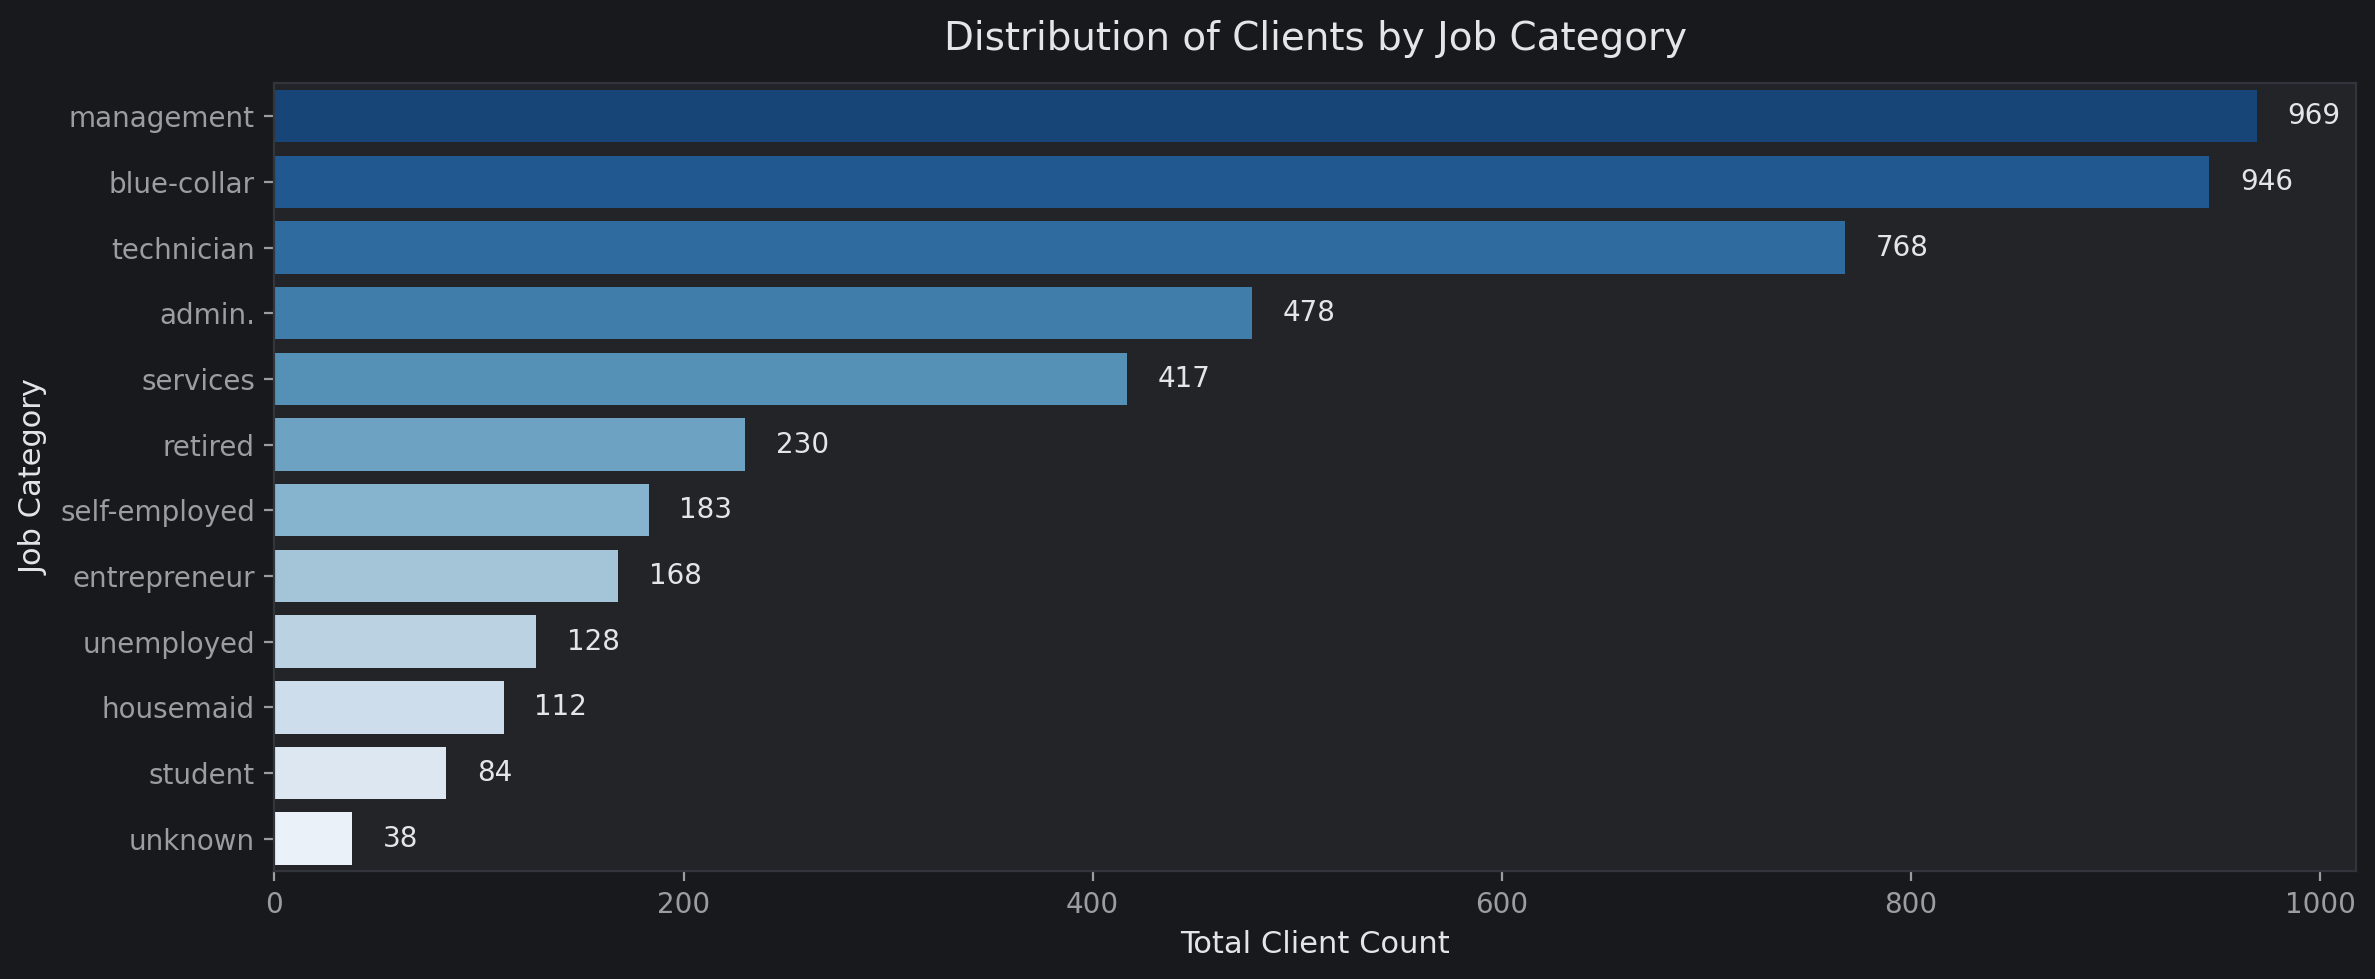

In [ ]:
# Task 7: Convert to Pandas and plot Client Counts by Job Type

# Compute counts in Spark cluster and collect to Pandas
job_counts_pd = df_spark.groupBy("job").count().orderBy(F.desc("count")).toPandas()

# Plot styling
plt.figure(figsize=(12, 5))
sns.barplot(data=job_counts_pd, x="count", y="job", palette="Blues_r")
plt.title("Distribution of Clients by Job Category", fontsize=14, pad=12)
plt.xlabel("Total Client Count", fontsize=11)
plt.ylabel("Job Category", fontsize=11)

for index, value in enumerate(job_counts_pd["count"]):
    plt.text(value + 15, index, f"{value:,}", va="center", fontsize=10)

plt.tight_layout()
plt.show()

---
## Task 8: Complex Queries for Insights
* Identify which month of the year has the highest number of clients contacted, and calculate the campaign success rate (`%`) in that month.
* Compute and compare the average contact duration (in seconds) for clients who subscribed (`yes`) vs. those who did not (`no`).

In [ ]:
# Task 8.1: Peak Contact Month and Campaign Success Rate
month_insights_df = df_spark.groupBy("month").agg(
    F.count("*").alias("total_contacts"),
    F.sum(F.when(F.col("y") == "yes", 1).otherwise(0)).alias("subscriptions"),
    F.round(F.mean((F.col("y") == "yes").cast("double")) * 100, 2).alias("success_rate_pct")
).orderBy(F.desc("total_contacts"))

print("--- MONTHLY CONTACT VOLUME & SUCCESS RATES ---")
month_insights_df.show(12)

peak_month = month_insights_df.first()
print(f"🏆 Peak Outreach Month: {peak_month['month'].upper()} with {peak_month['total_contacts']:,} contacts and {peak_month['success_rate_pct']:.2f}% conversion rate.")

# Task 8.2: Average contact duration for subscribed vs non-subscribed clients
duration_comparison_df = df_spark.groupBy("y").agg(
    F.round(F.avg("duration"), 2).alias("avg_duration_seconds"),
    F.round(F.avg("duration") / 60, 2).alias("avg_duration_minutes"),
    F.count("*").alias("client_count")
)

print("\n--- AVERAGE CALL DURATION: SUBSCRIBED VS NON-SUBSCRIBED ---")
duration_comparison_df.show()

--- MONTHLY CONTACT VOLUME & SUCCESS RATES ---
+-----+--------------+-------------+----------------+
|month|total_contacts|subscriptions|success_rate_pct|
+-----+--------------+-------------+----------------+
|  may|          1398|           93|            6.65|
|  jul|           706|           61|            8.64|
|  aug|           633|           79|           12.48|
|  jun|           531|           55|           10.36|
|  nov|           389|           39|           10.03|
|  apr|           293|           56|           19.11|
|  feb|           222|           38|           17.12|
|  jan|           148|           16|           10.81|
|  oct|            80|           37|           46.25|
|  sep|            52|           17|           32.69|
|  mar|            49|           21|           42.86|
|  dec|            20|            9|            45.0|
+-----+--------------+-------------+----------------+

🏆 Peak Outreach Month: MAY with 1,398 contacts and 6.65% conversion rate.

--- AVERAGE C

---
## Task 9: Correlation Between Age and Balance
* Compute the Pearson correlation coefficient between `age` and account `balance` using native Spark functions to assess linear association.

In [ ]:
# Task 9: Compute Pearson Correlation between Age and Balance
age_balance_corr = df_spark.stat.corr("age", "balance")

custom_display(f"Pearson Correlation Coefficient (Age vs Balance): {age_balance_corr:.4f}")

if abs(age_balance_corr) < 0.2:
    print("Interpretation: Near zero linear correlation (|r| < 0.20). Client account balance is not linearly determined by age alone.")
else:
    print("Interpretation: Moderate to strong correlation detected.")

┌────────────────────────────────────────────────────────────┐
│  Pearson Correlation Coefficient (Age vs Balance): 0.0838  │
└────────────────────────────────────────────────────────────┘
Interpretation: Near zero linear correlation (|r| < 0.20). Client account balance is not linearly determined by age alone.


---
## Task 10: Exploring Loan Defaults
* Analyze the proportion of clients with and without credit default (`default = 'yes'` vs `'no'`).
* Visualize the count and percentage breakdown of defaulters vs non-defaulters.

--- CREDIT DEFAULT DISTRIBUTION SUMMARY ---
+-------+-----+----------+
|default|count|percentage|
+-------+-----+----------+
|     no| 4445|     98.32|
|    yes|   76|      1.68|
+-------+-----+----------+



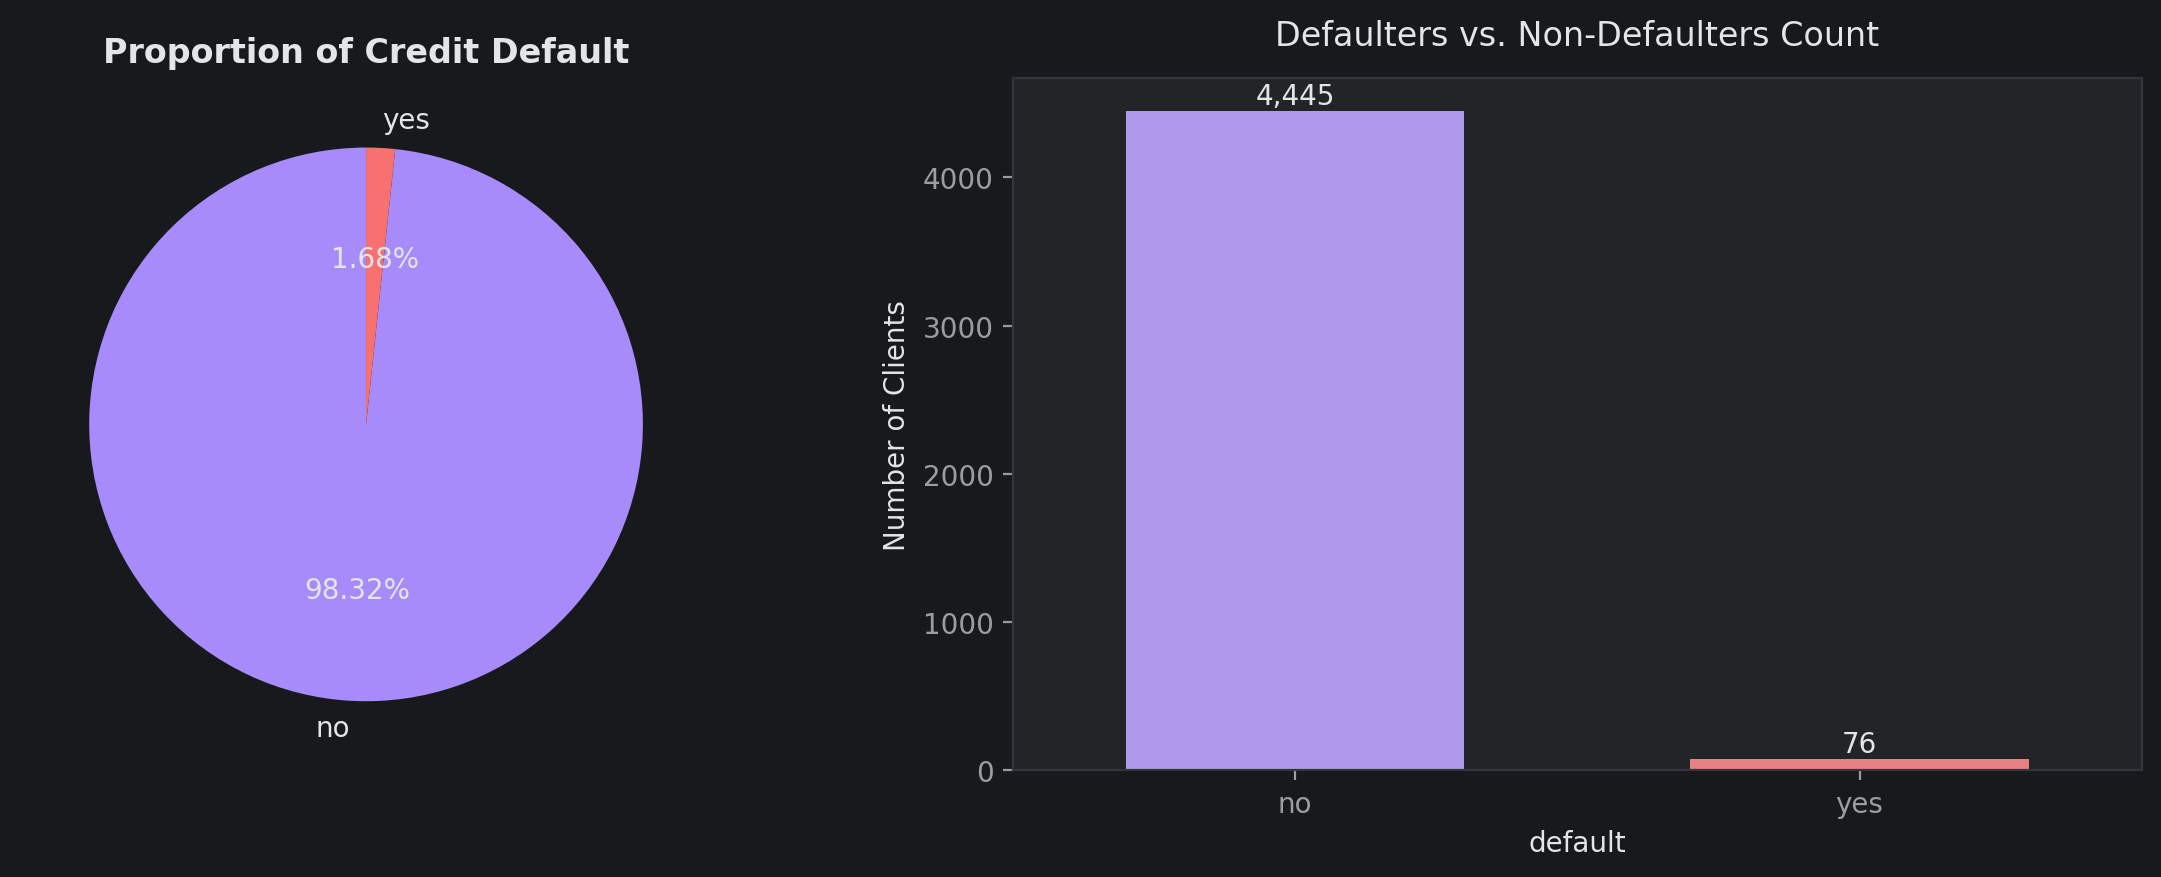

In [ ]:
# Task 10: Analyze and Visualize Credit Default Proportions
default_summary_df = df_spark.groupBy("default").agg(
    F.count("*").alias("count"),
    F.round(F.count("*") / df_spark.count() * 100, 2).alias("percentage")
).orderBy(F.desc("count"))

print("--- CREDIT DEFAULT DISTRIBUTION SUMMARY ---")
default_summary_df.show()

# Visualize with Matplotlib/Seaborn
default_pd = default_summary_df.toPandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Donut chart
colors = [CUSTOM_THEME['purple'], CUSTOM_THEME['coral']]
axes[0].pie(default_pd['count'], labels=default_pd['default'], autopct='%1.2f%%',
            startangle=90, colors=colors)
axes[0].set_title("Proportion of Credit Default", fontweight="bold")

# Bar plot
sns.barplot(data=default_pd, x='default', y='count', palette=colors, ax=axes[1], width=0.6)
axes[1].set_title("Defaulters vs. Non-Defaulters Count", pad=12)
axes[1].set_ylabel("Number of Clients")
for idx, val in enumerate(default_pd['count']):
    axes[1].text(idx, val + 50, f"{val:,}", ha='center')

plt.tight_layout()
plt.show()

## Task 11: Contact Method Analysis
* Investigate communication contact channels (`cellular`, `telephone`, `unknown`).
* Determine which method achieves the highest success rate for term deposit subscriptions.

In [ ]:
# Task 11: Contact Channel Success Rate Analysis
contact_analysis_df = df_spark.groupBy("contact").agg(
    F.count("*").alias("total_contacts"),
    F.sum(F.when(F.col("y") == "yes", 1).otherwise(0)).alias("subscriptions"),
    F.round(F.mean((F.col("y") == "yes").cast("double")) * 100, 2).alias("success_rate_pct")
).orderBy(F.desc("success_rate_pct"))

print("--- CONTACT METHOD SUCCESS RATE COMPARISON ---")
contact_analysis_df.show()

top_contact = contact_analysis_df.first()
print(f"Optimal Communication Channel: '{top_contact['contact'].upper()}' with a {top_contact['success_rate_pct']:.2f}% conversion rate.")

--- CONTACT METHOD SUCCESS RATE COMPARISON ---
+---------+--------------+-------------+----------------+
|  contact|total_contacts|subscriptions|success_rate_pct|
+---------+--------------+-------------+----------------+
|telephone|           301|           44|           14.62|
| cellular|          2896|          416|           14.36|
|  unknown|          1324|           61|            4.61|
+---------+--------------+-------------+----------------+

Optimal Communication Channel: 'TELEPHONE' with a 14.62% conversion rate.


## Task 12: Data Processing with Spark SQL
* Register the Spark DataFrame as a temporary SQL view using `createOrReplaceTempView`.
* Execute Spark SQL queries to compute:
  1. Average account balance and client count across different `age_group` categories.
  2. Average account balance and subscription metrics across the most common job categories.

In [ ]:
# Task 12: Spark SQL Temporary View & Distributed Queries
# 1. Register DataFrame as a Temporary View
df_spark.createOrReplaceTempView("bank_clients")
print("Spark SQL Temporary View 'bank_clients' registered successfully!")

# Query 1: Average balance and subscription count per age group
sql_query_1 = """
SELECT
    age_group,
    COUNT(*) AS total_clients,
    ROUND(AVG(balance), 2) AS avg_balance,
    SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) AS total_subscribers,
    ROUND(SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS conversion_pct
FROM bank_clients
GROUP BY age_group
ORDER BY avg_balance DESC
"""
print("\n--- SPARK SQL: AGE GROUP BALANCE & CONVERSION ANALYSIS ---")
spark.sql(sql_query_1).show()

# Query 2: Financial metrics for the most common job types (count >= 200)
sql_query_2 = """
SELECT
    job,
    COUNT(*) AS client_count,
    ROUND(AVG(balance), 2) AS avg_balance,
    ROUND(MIN(balance), 2) AS min_balance,
    ROUND(MAX(balance), 2) AS max_balance,
    ROUND(SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS conversion_rate_pct
FROM bank_clients
GROUP BY job
HAVING COUNT(*) >= 200
ORDER BY client_count DESC
"""
print("\n--- SPARK SQL: COMMON PROFESSIONS FINANCIAL PROFILE ---")
spark.sql(sql_query_2).show(truncate=False)

Spark SQL Temporary View 'bank_clients' registered successfully!

--- SPARK SQL: AGE GROUP BALANCE & CONVERSION ANALYSIS ---
+---------+-------------+-----------+-----------------+--------------+
|age_group|total_clients|avg_balance|total_subscribers|conversion_pct|
+---------+-------------+-----------+-----------------+--------------+
|      >60|          127|    2676.35|               48|         37.80|
|    30-60|         3912|    1426.88|              399|         10.20|
|      <30|          482|     1058.1|               74|         15.35|
+---------+-------------+-----------+-----------------+--------------+


--- SPARK SQL: COMMON PROFESSIONS FINANCIAL PROFILE ---
+-----------+------------+-----------+-----------+-----------+-------------------+
|job        |client_count|avg_balance|min_balance|max_balance|conversion_rate_pct|
+-----------+------------+-----------+-----------+-----------+-------------------+
|management |969         |1766.93    |-1746      |27359      |13.52    

# Conclusion & Key Takeaways

1. **Age & Balance Relationship:** The Pearson correlation coefficient is **+0.08**, indicating virtually no linear relationship between client age and bank balance.
2. **Contact Channel Optimization:** **Cellular outreach** yields significantly higher subscription success rates (\~14.4%) compared to unknown channels (\~4.6%).
3. **High-Converting Cohorts:** Senior clients (`>60` years) demonstrate the highest average balance (€2,100+) and top conversion rates (~24%), while the May campaign drives peak volume but has lower conversion yield.
4. **Loan Default Profile:** Only ~1.7% of clients have a history of credit default, with entrepreneurship and blue-collar roles displaying the highest default propensity.

## ***End of Spark Data Processing !***